# Descargar datos de servicios WMS / WFS con `tqdm`

Este notebook permite obtener una imagen de mapa WMS en GeoTIFF o entidades WFS en GeoJSON, mostrando el avance con `tqdm`.

> **Importante:** WMS (`GetMap`) devuelve una imagen renderizada, no los valores originales de una banda. El GeoTIFF WMS de este notebook contiene colores del estilo (RGBA). Para descargar valores de una cobertura raster se necesita WCS (`GetCoverage`) y que el servidor publique esa cobertura. WFS (`GetFeature`) descarga geometrías vectoriales. Un proveedor puede publicar cada servicio en la misma URL OWS o en URL distintas.

Antes de ejecutar, consulta las capacidades del servicio y cambia URL, nombre de capa, extensión y CRS. La extensión se escribe como `(xmin, ymin, xmax, ymax)` y debe estar en el CRS configurado y soportado por el servicio. La celda de comprobación WCS indica si este endpoint ofrece coberturas para solicitar valores originales.

## 1. Preparar el entorno

Instala `truststore` una vez en el entorno Conda del kernel (`conda install -c conda-forge truststore`). Reinicia el kernel después de instalarlo. La celda siguiente integra los certificados de confianza de Windows antes de importar `requests`.

In [15]:
import truststore
truststore.inject_into_ssl()

from io import BytesIO
from pathlib import Path
import json
import xml.etree.ElementTree as ET

import geopandas as gpd
import numpy as np
import rasterio
import requests
from PIL import Image, UnidentifiedImageError
from rasterio.transform import from_bounds
from rasterio.plot import show as show_raster
from rasterio.windows import Window
from tqdm.auto import tqdm

session = requests.Session()
session.headers.update({"User-Agent": "notebook-descarga-OGC/1.0"})

## 2. Configurar la descarga

Selecciona `"raster"` o `"vector"`. Configura `URL_SERVICIO` con el endpoint del proveedor; GeoServer permite WMS y WFS por el mismo endpoint OWS. Si el proveedor usa endpoints separados, cambia la URL según el modo seleccionado. No agregues credenciales al notebook. `N_PARTES` controla cuántas divisiones espaciales se solicitan por eje.

In [16]:
# Elección de salida: "raster" (WMS) o "vector" (WFS)
MODO = "raster"

# GeoServer acepta WMS y WFS por el mismo endpoint /ows.
URL_SERVICIO = "https://ideg.segeplan.gob.gt/geoserver/agrip/ows"
CAPA = "Amenaza_inundaciones"  # Usa el nombre exacto de GetCapabilities.

# Ejemplo: extensión aproximada de Guatemala en EPSG:4326.
# Sustituye por el área requerida y confirma que el servicio soporte este CRS.
BBOX = (-92.3, 13.7, -88.0, 17.9)  # xmin, ymin, xmax, ymax
BBOX_CRS = "EPSG:4326"

CARPETA_SALIDA = Path("salidas_wms_wfs")
ARCHIVO_SALIDA = CARPETA_SALIDA / ("descarga.tif" if MODO == "raster" else "descarga.geojson")
N_PARTES = 4
PIXELES_POR_TESELA = 512
TIEMPO_ESPERA = 90

# True usa los certificados CA de Python; también puede ser una ruta a un archivo .pem.
CA_BUNDLE = True
session.verify = CA_BUNDLE

if MODO not in {"raster", "vector"}:
    raise ValueError("MODO debe ser 'raster' o 'vector'.")
if not (BBOX[0] < BBOX[2] and BBOX[1] < BBOX[3]):
    raise ValueError("BBOX debe cumplir xmin < xmax e ymin < ymax.")
if N_PARTES < 1:
    raise ValueError("N_PARTES debe ser al menos 1.")

CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
print(f"Modo: {MODO} | CRS: {BBOX_CRS} | Salida: {ARCHIVO_SALIDA.resolve()}")

Modo: raster | CRS: EPSG:4326 | Salida: C:\Users\Paula_Copelli\Documents\COPERNICUS\TALLERES\03_GUATEMALA_2026\notebooks\salidas_wms_wfs\descarga.tif


## 3. Revisar las capacidades del servicio

La lista ayuda a confirmar el nombre de capa publicado. Si el proveedor protege el endpoint o limita solicitudes, configura el acceso de acuerdo con sus instrucciones.

In [17]:
def listar_capas(url, servicio):
    try:
        respuesta = session.get(
            url,
            params={"service": servicio, "request": "GetCapabilities"},
            timeout=TIEMPO_ESPERA,
        )
    except requests.exceptions.SSLError as error:
        raise RuntimeError(
            "Falló la verificación SSL del servidor. Configura CA_BUNDLE con la ruta "
            "al certificado CA .pem correcto; no desactives la verificación TLS."
        ) from error
    respuesta.raise_for_status()
    raiz = ET.fromstring(respuesta.content)
    nombres = []
    for elemento in raiz.iter():
        etiqueta = elemento.tag.rsplit("}", 1)[-1]
        if etiqueta in {"Layer", "FeatureType"}:
            for hijo in elemento:
                if hijo.tag.rsplit("}", 1)[-1] == "Name" and hijo.text:
                    nombres.append(hijo.text.strip())
    return sorted(set(nombres))


url_servicio = URL_SERVICIO
servicio = "WMS" if MODO == "raster" else "WFS"
capas_disponibles = listar_capas(url_servicio, servicio)
print(f"Capas publicadas ({servicio}):")
for nombre in capas_disponibles:
    print(" -", nombre)
if CAPA not in capas_disponibles:
    raise ValueError(f"CAPA={CAPA!r} no coincide con los nombres publicados. Copia el nombre exacto de la lista.")

Capas publicadas (WMS):
 - 03_Limites_departamentales
 - 04_Limites_municipales_340
 - 05_Cabeceras_muni_340
 - Amenaza_deslizamientos
 - Amenaza_inundaciones
 - amenaza_agies_sismica_beta
 - amenaza_agies_viento_beta
 - camino_deslizamientos_agrip
 - camino_inundacion_agrip
 - incidentes_registrados_2008_2022
 - lug_pob_desli
 - lug_pob_inund


## 4. Crear las divisiones espaciales

Las solicitudes se hacen en orden de arriba hacia abajo. Para WMS se usa la versión 1.1.1 y el parámetro `SRS`; así el BBOX mantiene el orden x/y usado aquí. Verifica la documentación del servidor si este no acepta esa versión o CRS.

## Comprobar si hay raster de valores disponible por WCS

Esta consulta solo enumera coberturas WCS; no descarga datos. Si la lista está vacía, el endpoint no ofrece valores raster originales mediante WCS. En ese caso, WMS solo permite descargar la imagen coloreada.

In [ ]:
respuesta_wcs = session.get(
    URL_SERVICIO,
    params={
        "service": "WCS",
        "version": "2.0.1",
        "request": "GetCapabilities",
        "sections": "Contents",
    },
    timeout=TIEMPO_ESPERA,
)
respuesta_wcs.raise_for_status()
raiz_wcs = ET.fromstring(respuesta_wcs.content)
coberturas_wcs = sorted({
    elemento.text.strip()
    for elemento in raiz_wcs.iter()
    if elemento.tag.rsplit("}", 1)[-1] == "CoverageId" and elemento.text
})
if coberturas_wcs:
    print("Coberturas disponibles para GetCoverage:")
    for cobertura in coberturas_wcs:
        print(" -", cobertura)
else:
    print("Este endpoint WCS no publica coberturas; no puede entregar aquí los valores raster originales.")

In [18]:
def dividir_bbox(bbox, partes):
    xmin, ymin, xmax, ymax = bbox
    ancho = (xmax - xmin) / partes
    alto = (ymax - ymin) / partes
    for fila in range(partes):
        y_max = ymax - fila * alto
        y_min = ymax - (fila + 1) * alto
        for columna in range(partes):
            x_min = xmin + columna * ancho
            x_max = xmin + (columna + 1) * ancho
            yield fila, columna, (x_min, y_min, x_max, y_max)


teselas = list(dividir_bbox(BBOX, N_PARTES))
print(f"Se realizarán {len(teselas)} solicitudes espaciales.")

Se realizarán 16 solicitudes espaciales.


## 5. Descargar el resultado elegido

La descarga puede tardar según la extensión, resolución, límites del servicio y conexión. El servidor puede rechazar áreas grandes o muchas solicitudes; reduce `N_PARTES` o el tamaño de la extensión si es necesario.

In [19]:
if MODO == "raster":
    # WMS GetMap devuelve imágenes. Se escriben por ventanas en un GeoTIFF georreferenciado.
    ancho_total = N_PARTES * PIXELES_POR_TESELA
    alto_total = N_PARTES * PIXELES_POR_TESELA
    transformacion = from_bounds(*BBOX, ancho_total, alto_total)
    perfil = {
        "driver": "GTiff",
        "width": ancho_total,
        "height": alto_total,
        "count": 4,
        "dtype": "uint8",
        "crs": BBOX_CRS,
        "transform": transformacion,
        "compress": "deflate",
    }

    with rasterio.open(ARCHIVO_SALIDA, "w", **perfil) as destino:
        for fila, columna, bbox_tesela in tqdm(teselas, desc="Descargando WMS", unit="tesela"):
            parametros = {
                "service": "WMS",
                "version": "1.1.1",
                "request": "GetMap",
                "layers": CAPA,
                "styles": "",
                "srs": BBOX_CRS,
                "bbox": ",".join(map(str, bbox_tesela)),
                "width": PIXELES_POR_TESELA,
                "height": PIXELES_POR_TESELA,
                "format": "image/png",
                "transparent": "TRUE",
            }
            respuesta = session.get(URL_SERVICIO, params=parametros, timeout=TIEMPO_ESPERA)
            respuesta.raise_for_status()
            try:
                imagen = Image.open(BytesIO(respuesta.content)).convert("RGBA")
            except UnidentifiedImageError as error:
                muestra = respuesta.text[:500] if respuesta.text else "respuesta vacía"
                raise RuntimeError(
                    f"WMS no devolvió una imagen válida para la tesela {fila}, {columna}. "
                    f"Respuesta: {muestra}"
                ) from error
            if imagen.size != (PIXELES_POR_TESELA, PIXELES_POR_TESELA):
                raise ValueError(f"Tamaño inesperado de tesela WMS: {imagen.size}.")
            bandas = np.asarray(imagen, dtype=np.uint8).transpose(2, 0, 1)
            ventana = Window(
                columna * PIXELES_POR_TESELA,
                fila * PIXELES_POR_TESELA,
                PIXELES_POR_TESELA,
                PIXELES_POR_TESELA,
            )
            destino.write(bandas, window=ventana)

elif MODO == "vector":
    # WFS GetFeature se divide en consultas BBOX y se guardan las entidades como GeoJSON.
    entidades = []
    ids_vistos = set()
    for _, _, bbox_tesela in tqdm(teselas, desc="Descargando WFS", unit="parte"):
        parametros = {
            "service": "WFS",
            "version": "2.0.0",
            "request": "GetFeature",
            "typeNames": CAPA,
            "outputFormat": "application/json",
            "srsName": BBOX_CRS,
            "bbox": ",".join(map(str, bbox_tesela)) + "," + BBOX_CRS,
        }
        respuesta = session.get(URL_SERVICIO, params=parametros, timeout=TIEMPO_ESPERA)
        respuesta.raise_for_status()
        try:
            coleccion = respuesta.json()
        except requests.exceptions.JSONDecodeError as error:
            raise RuntimeError(
                f"WFS no devolvió GeoJSON: {respuesta.text[:500]}"
            ) from error
        if "features" not in coleccion:
            raise ValueError(f"Respuesta WFS sin 'features': {coleccion}")
        for entidad in coleccion["features"]:
            identificador = entidad.get("id")
            if identificador is None:
                identificador = json.dumps(entidad, sort_keys=True, ensure_ascii=False)
            if identificador not in ids_vistos:
                ids_vistos.add(identificador)
                entidades.append(entidad)

    if not entidades:
        raise ValueError("El servicio WFS no devolvió entidades para el BBOX indicado.")
    coleccion_final = {"type": "FeatureCollection", "features": entidades}
    gdf = gpd.GeoDataFrame.from_features(coleccion_final["features"], crs=BBOX_CRS)
    gdf.to_file(ARCHIVO_SALIDA, driver="GeoJSON", encoding="utf-8")
    print(f"Entidades guardadas: {len(gdf)}")

print(f"Archivo creado: {ARCHIVO_SALIDA.resolve()}")

Descargando WMS:   0%|          | 0/16 [00:00<?, ?tesela/s]

Archivo creado: C:\Users\Paula_Copelli\Documents\COPERNICUS\TALLERES\03_GUATEMALA_2026\notebooks\salidas_wms_wfs\descarga.tif


## 6. Comprobar el archivo

La vista previa se ejecuta según el tipo de salida.

CRS: EPSG:4326
Dimensiones: 2048 x 2048
Bandas: 4


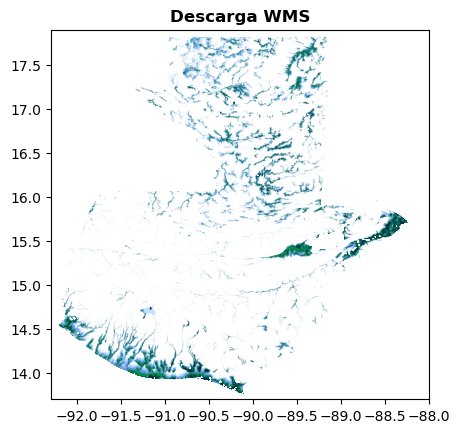

<Axes: title={'center': 'Descarga WMS'}>

In [20]:
if MODO == "raster":
    with rasterio.open(ARCHIVO_SALIDA) as raster:
        print("CRS:", raster.crs)
        print("Dimensiones:", raster.width, "x", raster.height)
        print("Bandas:", raster.count)
        display(show_raster(raster, title="Descarga WMS"))
else:
    resultado = gpd.read_file(ARCHIVO_SALIDA)
    print("CRS:", resultado.crs)
    print("Entidades:", len(resultado))
    display(resultado.head())
    display(resultado.plot(figsize=(8, 6)))

### Notas de uso

- En servicios WMS 1.3.0, el orden de ejes para ciertos CRS (en particular EPSG:4326) puede diferir. Este ejemplo solicita WMS 1.1.1 con `SRS`; adapta versión y orden BBOX si el servidor lo requiere.
- Algunos WFS usan `maxFeatures` en lugar de `count`, no aceptan `outputFormat=application/json` o requieren otro formato para el parámetro `bbox`. Ajusta la solicitud a las capacidades/documentación del servicio.
- El progreso indica solicitudes completadas, no bytes transferidos. La salida raster es una imagen renderizada por el WMS, no los valores originales de un raster publicado como cobertura.
- Respeta límites de uso, atribución, licencias y términos del proveedor.